# Digital Image Processing Assignment
## Smart Image Enhancement and Object Detection Using Python & OpenCV

**Members:** Safeer - 024, Suhayl - 032, Akmal - 034, Shaheem - 033

### The big picture
We build a small pipeline (without deep learning models, with the traditional methods)

`Load -> Resize -> Grayscale -> Blur (Gaussian) -> Threshold -> Edges -> Mask -> Contours -> Filters -> Boxes -> Count`

Github repository with the full implementation with the output images and the single page report: https://github.com/safeer-zubair/smart-image-enhancement-object-detection.git

# 1. Setup
Import the libraries and setting up the environment for the pipeline

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR="."
OUTPUT_DIR="outputs"
IMAGE_NAME="01_clean_objects.png"
IMAGE_PATH = os.path.join(IMAGE_DIR, IMAGE_NAME)

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("OpenCV version:", cv2.__version__)
print("Working on    :", IMAGE_PATH)

OpenCV version: 5.0.0
Working on    : .\01_clean_objects.png


In [2]:
# Helper function to show image or images

def show(img, title, save_as=None, figsize=(5, 5)):
    plt.figure(figsize=figsize)
    if img.ndim == 2:
        plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
             
    if save_as:
        plt.savefig(os.path.join(OUTPUT_DIR, save_as), bbox_inches="tight", dpi=120)
    plt.show()

def show_row(images, titles, save_as=None, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles), start=1):
        plt.subplot(1, len(images), i)
        if im.ndim == 2:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        plt.title(t)
        plt.axis("off")
    if save_as:
        plt.savefig(os.path.join(OUTPUT_DIR, save_as), bbox_inches="tight", dpi=120)
    plt.show()

# 2. Task 1: Image Preprocessing

## 2.1 Load the image and verify it loaded

Image loaded successfully!
Original shape: (480, 700, 3)
Data type: uint8


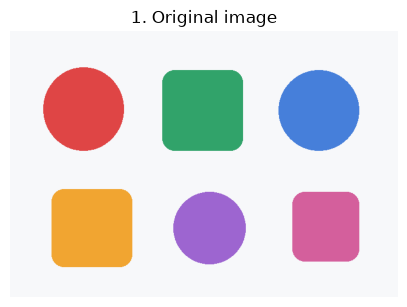

In [3]:
img_original = cv2.imread(IMAGE_PATH)

if img_original is None:
    raise FileNotFoundError(f"Could not find the image in the path: {IMAGE_PATH}, check the file name and the folder.")

print("Image loaded successfully!")
print("Original shape:", img_original.shape)
print("Data type:", img_original.dtype)
show(img_original, "1. Original image", "task1_original.png")

## 2.2 Resize it to exactly (500 x 500) and show the dimensions

Resized shape: (500, 500, 3)
Width x Height: 500 x 500


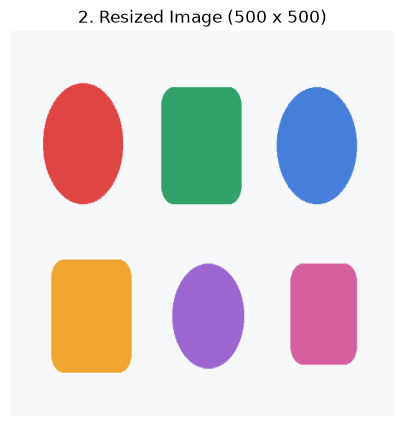

In [4]:
img = cv2.resize(img_original, (500, 500))

print("Resized shape:", img.shape)
print("Width x Height:", img.shape[1], "x", img.shape[0])
show(img, "2. Resized Image (500 x 500)", "task1_resized.png")

## 2.3 Convert BGR to Grayscale

Grayscale image shape: (500, 500)


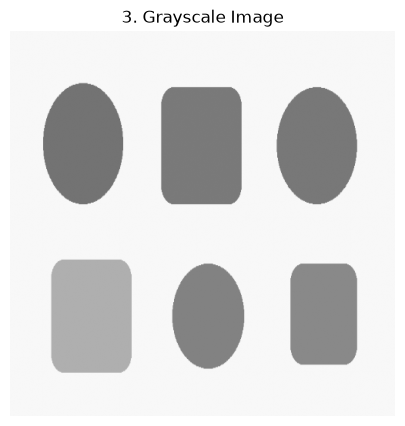

In [5]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Grayscale image shape:", gray.shape)
show(gray, "3. Grayscale Image", "task1_gray.png")

## 2.4 Gaussian blur with valid odd kernel size

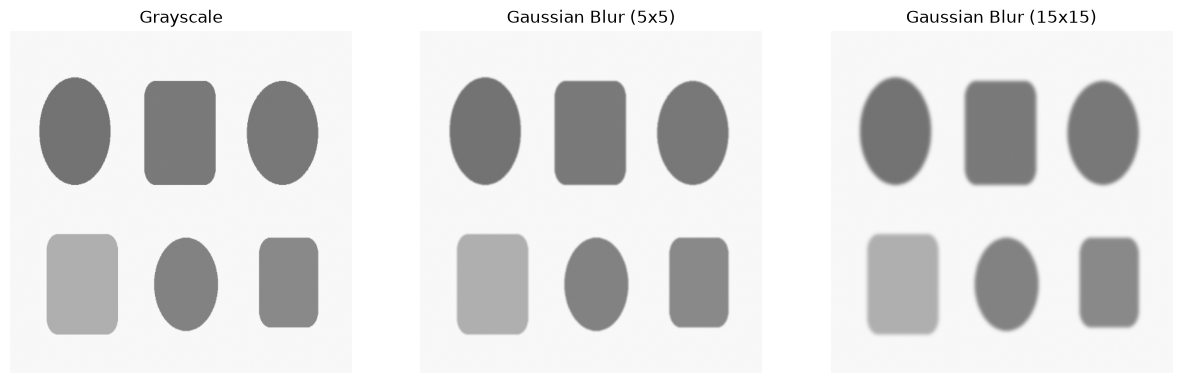

In [6]:
blur3 = cv2.GaussianBlur(gray, (3,3), 0)
blur5 = cv2.GaussianBlur(gray, (5,5), 0)
blur15 = cv2.GaussianBlur(gray, (15,15), 0)

blurred = blur5

show_row(
    [gray, blur5, blur15],
    ["Grayscale", "Gaussian Blur (5x5)", "Gaussian Blur (15x15)"],
    "task1_blur_comparison.png"
)

The 5x5 blur is a “smoothing” of minor random intensity variations (noise) while preserving the outline of the object. The 15×15 blur effect clearly reduces the sharpness of the image, potentially altering the outline or fusing parts of the image together. A small odd kernel (5×5) is therefore used which is a compromise between noise reduction and edge preservation.

# 3. Task 2: Thresholding

## 3.0 Histogram

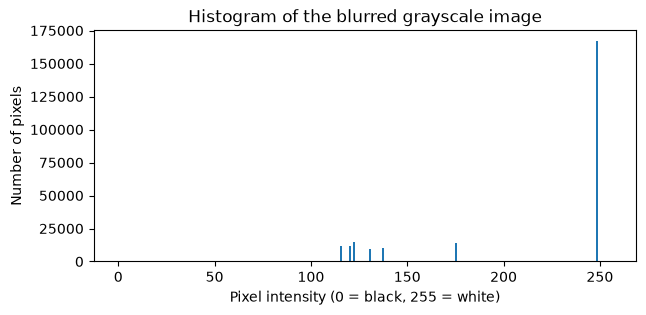

In [7]:
plt.figure(figsize=(7, 3))
plt.hist(blurred.ravel(), bins=256, range=(0, 256))
plt.title("Histogram of the blurred grayscale image")
plt.xlabel("Pixel intensity (0 = black, 255 = white)")
plt.ylabel("Number of pixels")
plt.show()

## 3.1 Global binary thresholding

Manual threshold: 180
Otsu threshold  : 191.0


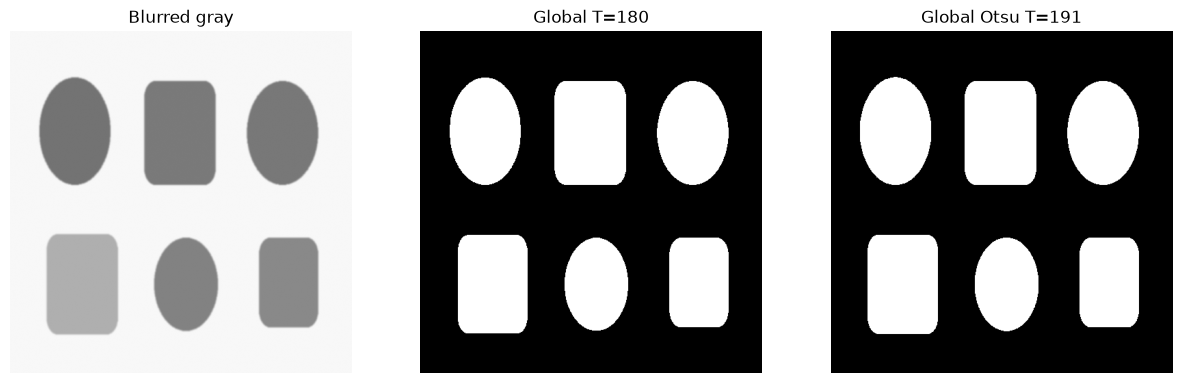

In [8]:
# Manually chosen threshold
T_manual = 180
_, global_manual = cv2.threshold(blurred, T_manual, 255, cv2.THRESH_BINARY_INV)

# Otsu's method
T_otsu, global_otsu = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

print("Manual threshold:", T_manual)
print("Otsu threshold  :", T_otsu)
show_row([blurred, global_manual, global_otsu],
         ["Blurred gray", f"Global T={T_manual}", f"Global Otsu T={T_otsu:.0f}"],
         "task2_global.png")

The histogram has a high peak around 248 (pale area) and the lower values come from the objects (mean gray 115 to 175). We experimented with a manual T = (180) and Otsu's method which has chosen an automatic T = (191) between the groups by itself. We use Otsu as it is not related to our guess, a fixed 127 would not include the lighter objects.

### Why we selected Oslu's method

The histogram of the clean image is blurred, but has two distinct groups: a high peak is seen around 248 (the pale background), and lower values are seen for the objects (mean gray around 115-175). Otsu's method automatically scans all 256 possible thresholds and selects the one that most effectively separates these two groups of pixels from each other (the one that minimises the variance inside each group). Was selected because:

1. **It is objective.** We didn't have to guess. Our T = 180 worked, but was just a few levels above our brightest object (~175), with Otsu selecting T = 191 which was in the middle of the gap.
It uses different threshold for each image (Otsu chose 191 for the clean image and 185 for the noisy image, and 201 for a counting challenge image), so no need to retune a fixed number.
3. It's easy and repeatable.It is easy and repeatable for anybody running the notebook.

Limitation: Otsu is a single-threshold method, and works only if there are two distinct peaks in the histogram. This assumption becomes invalid when the intensity of the background light varies over the image (uneven lighting) (see next section).

## 3.2 Adaptive thresholding

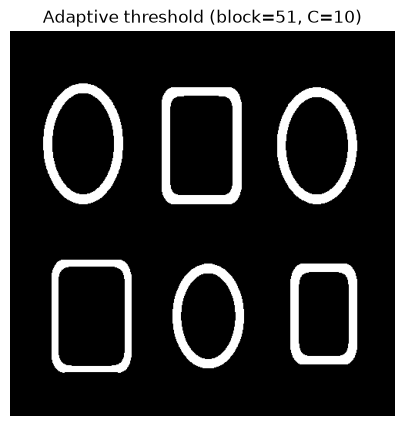

In [9]:
BLOCK_SIZE = 51
C_VALUE    = 10

adaptive = cv2.adaptiveThreshold(
    blurred,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    BLOCK_SIZE,
    C_VALUE)

show(adaptive, f"Adaptive threshold (block={BLOCK_SIZE}, C={C_VALUE})", "task2_adaptive.png")

Block size 51 (odd) is bigger than the fine detail but not too large to follow the lighting changes. The local mean is subtracted by 10 to avoid indicating brightness variations on the background as foreground. The larger C is the stricter it is and can lose "faint" objects.

## 3.3 Side by side comparison

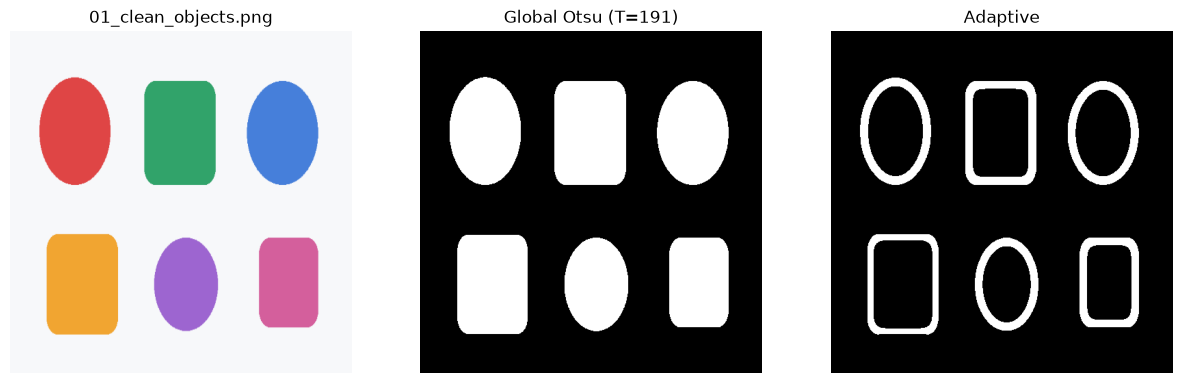

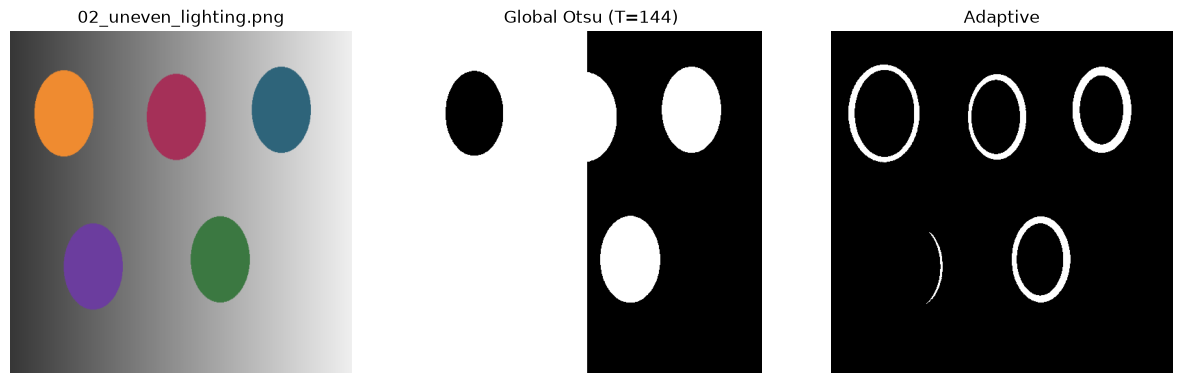

In [10]:
def threshold_both(path):
    im = cv2.imread(path)
    if im is None:
        raise FileNotFoundError(path)
    im = cv2.resize(im, (500, 500))
    g = cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    t, glob = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    ad = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv2.THRESH_BINARY_INV, BLOCK_SIZE, C_VALUE)
    return im, g, glob, ad, t

for name in ["01_clean_objects.png", "02_uneven_lighting.png"]:
    im, g, glob, ad, t = threshold_both(os.path.join(IMAGE_DIR, name))
    show_row([im, glob, ad],
             [f"{name}", f"Global Otsu (T={t:.0f})", "Adaptive"],
             f"task2_compare_{name[:2]}.png")

The masks obtained with both methods are very similar on the clean image since the background area is uniform. The image is unevenly lit and a single global threshold cannot be used for both the left and right side of the image, thus the outcome is incorrect (just 3 objects were detected). Adaptive thresholding compares the intensity of each pixel to its neighbourhood and is better at dealing with the gradient, but fails to detect the crimson circle (4 of 5 found) since the intensity of the circle is very close to that of the background.

# 4. Task 3: Edge Detection

## 4.1 Sobel

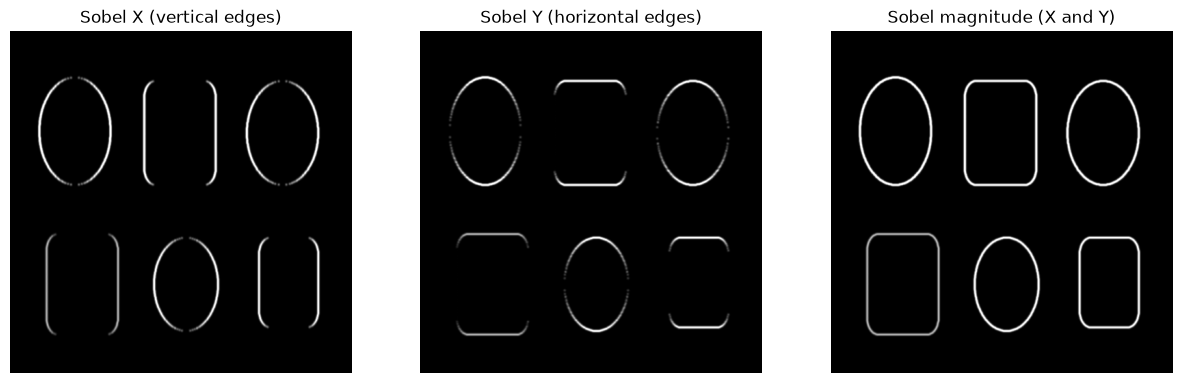

In [11]:
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

sobel_mag = cv2.magnitude(sobel_x, sobel_y)

sobel_x_8   = cv2.convertScaleAbs(sobel_x)
sobel_y_8   = cv2.convertScaleAbs(sobel_y)
sobel_mag_8 = cv2.convertScaleAbs(sobel_mag)

show_row([sobel_x_8, sobel_y_8, sobel_mag_8],
         ["Sobel X (vertical edges)", "Sobel Y (horizontal edges)", "Sobel magnitude (X and Y)"],
         "task3_sobel.png")

## 4.2 Canny

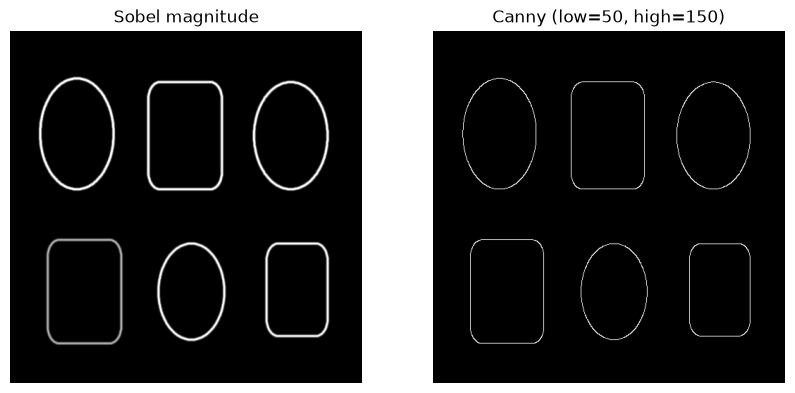

In [12]:
CANNY_LOW, CANNY_HIGH = 50, 150
canny = cv2.Canny(blurred, CANNY_LOW, CANNY_HIGH)

show_row([sobel_mag_8, canny],
         ["Sobel magnitude", f"Canny (low={CANNY_LOW}, high={CANNY_HIGH})"],
         "task3_canny.png", figsize=(10, 5))

## 4.3 Compare thickness, noise sensitivity and thresholds

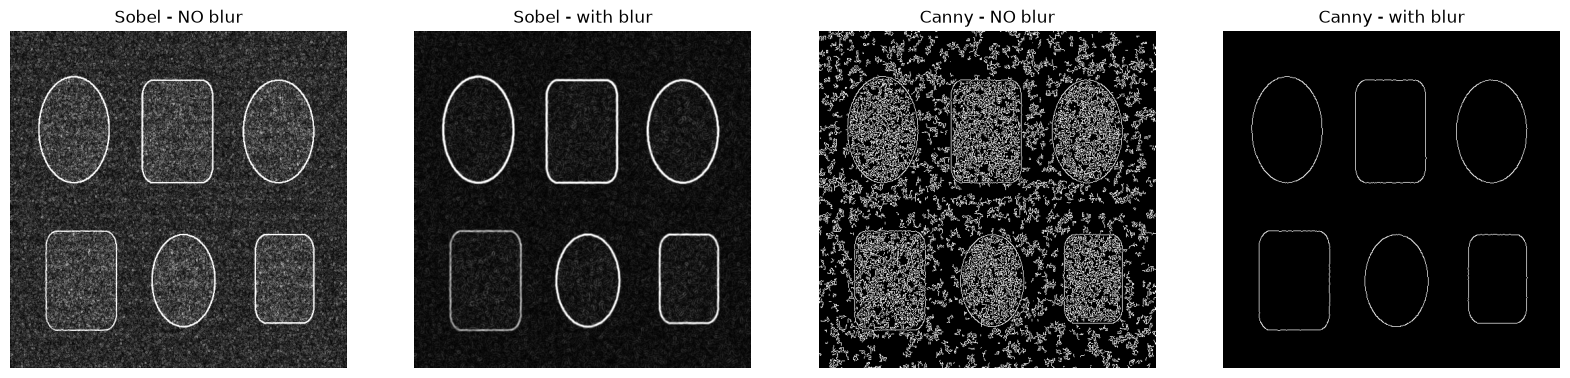

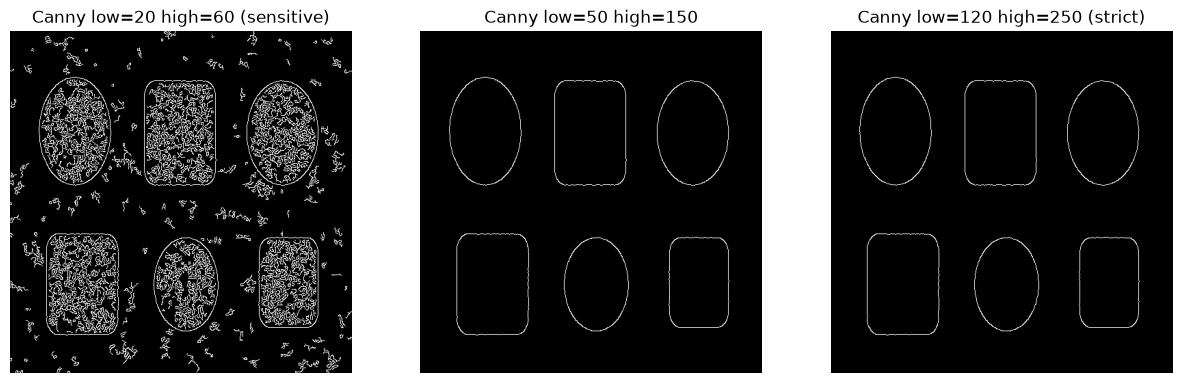

In [13]:
noisy = cv2.resize(cv2.imread(os.path.join(IMAGE_DIR, "03_noisy_objects.png")), (500, 500))
noisy_gray = cv2.cvtColor(noisy, cv2.COLOR_BGR2GRAY)
noisy_blur = cv2.GaussianBlur(noisy_gray, (5, 5), 0)

def sobel_8(g):
    gx = cv2.Sobel(g, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_64F, 0, 1, ksize=3)
    return cv2.convertScaleAbs(cv2.magnitude(gx, gy))

show_row([sobel_8(noisy_gray), sobel_8(noisy_blur),
          cv2.Canny(noisy_gray, 50, 150), cv2.Canny(noisy_blur, 50, 150)],
         ["Sobel - NO blur", "Sobel - with blur",
          "Canny - NO blur", "Canny - with blur"],
         "task3_noise_comparison.png", figsize=(20, 5))

show_row([cv2.Canny(noisy_blur, 20, 60), cv2.Canny(noisy_blur, 50, 150), cv2.Canny(noisy_blur, 120, 250)],
         ["Canny low=20 high=60 (sensitive)", "Canny low=50 high=150", "Canny low=120 high=250 (strict)"],
         "task3_canny_thresholds.png")

| Feature | Sobel | Canny |
| --- | --- | --- |
| Edge thickness | Thick, several pixels, grayscale strength map | Thin, 1 pixel, binary |
| Noise sensitivity | High: noise appears as grain | High without blur (many fragments), reduced with blur |
| Parameters | Kernel size only | Low and high thresholds (hysteresis) |

When thresholds are low (20/60), the edges of the noise areas are preserved; when thresholds are high (120/250), the edges of the noise areas are broken. Blurring first, enhances both.

# 5. Task 4: Contour based object detection

## 5.1 Foreground mask

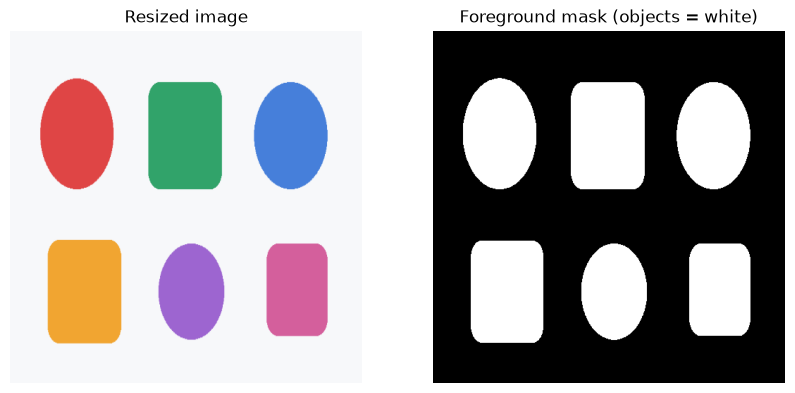

In [14]:
def make_mask(img_bgr, method="otsu"):
    if method in ("otsu", "adaptive"):
        g = cv2.GaussianBlur(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (5, 5), 0)
        if method == "otsu":
            _, m = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        else:
            m = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                      cv2.THRESH_BINARY_INV, BLOCK_SIZE, C_VALUE)
    elif method == "saturation":
        hsv = cv2.cvtColor(cv2.GaussianBlur(img_bgr, (5, 5), 0), cv2.COLOR_BGR2HSV)
        s = hsv[:, :, 1]
        _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        raise ValueError("method must be 'otsu', 'adaptive' or 'saturation'")
    return m

mask = make_mask(img, "otsu")
show_row([img, mask], ["Resized image", "Foreground mask (objects = white)"], "task4_mask.png", figsize=(10, 5))

## 5.2 Extract contours

In [15]:
contours, hierarchy = cv2.findContours(mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("Raw number of contours found (before filtering):", len(contours))

Raw number of contours found (before filtering): 6


## 5.3 Reject small noise contours with a documented area threshold

In [16]:
MIN_AREA = 500

areas = sorted([cv2.contourArea(c) for c in contours])
print("All contour areas:", [int(a) for a in areas])

valid_contours = [c for c in contours if cv2.contourArea(c) >= MIN_AREA]
print(f"Kept {len(valid_contours)} valid contours, rejected {len(contours) - len(valid_contours)} small ones")

All contour areas: [9880, 10852, 12304, 12761, 14393, 15380]
Kept 6 valid contours, rejected 0 small ones


Real objects are at least about 5,000 px (with the smallest on image 05), and are usually 10,000–15,000 px, and a noise speck is a few pixels. MIN_AREA> 500 is definitely above noise and is much smaller than any real object.

## 5.4 & 5.5 Bounding rectangles and count overlay

FINAL OBJECT COUNT: 6


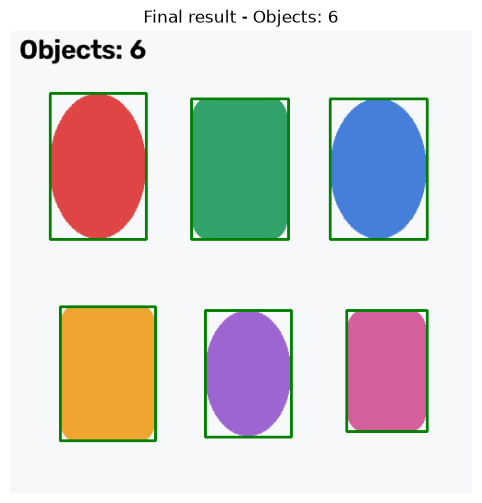

In [17]:
result = img.copy()

for c in valid_contours:
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(result, (x, y), (x + w, y + h), (0, 128, 0), 2)

count = len(valid_contours)
cv2.putText(result, f"Objects: {count}", (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0), 2)

print("FINAL OBJECT COUNT:", count)
show(result, f"Final result - Objects: {count}", "task4_final_01.png", figsize=(6, 6))

## 5.6 Wrap everything into a function and test with all the images

In [18]:
def detect_objects(path, method="otsu", min_area=MIN_AREA):
    im = cv2.imread(path)
    if im is None:
        raise FileNotFoundError(path)
    im = cv2.resize(im, (500, 500))
    m = make_mask(im, method)
    cnts, _ = cv2.findContours(m.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    valid = [c for c in cnts if cv2.contourArea(c) >= min_area]
    out = im.copy()
    for c in valid:
        x, y, w, h = cv2.boundingRect(c)
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 128, 0), 2)
    cv2.putText(out, f"Objects: {len(valid)}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0), 2)
    return out, m, len(valid), len(cnts)

images = ["01_clean_objects.png", "02_uneven_lighting.png", "03_noisy_objects.png",
          "04_touching_objects.png", "05_counting_challenge.png"]
expected = {"01_clean_objects.png": 6, "02_uneven_lighting.png": 5, "03_noisy_objects.png": 6,
            "04_touching_objects.png": 4, "05_counting_challenge.png": 6}

print(f"{'image':28s}{'method':12s}{'expected':>9s}{'detected':>9s}{'raw':>6s}   ok?")
for name in images:
    for method in ["otsu", "adaptive", "saturation"]:
        _, _, n, raw = detect_objects(os.path.join(IMAGE_DIR, name), method)
        print(f"{name:28s}{method:12s}{expected[name]:9d}{n:9d}{raw:6d}   {'YES' if n == expected[name] else 'NO'}")

image                       method       expected detected   raw   ok?
01_clean_objects.png        otsu                6        6     6   YES
01_clean_objects.png        adaptive            6        6     6   YES
01_clean_objects.png        saturation          6        6     6   YES
02_uneven_lighting.png      otsu                5        3     3   NO
02_uneven_lighting.png      adaptive            5        4     5   NO
02_uneven_lighting.png      saturation          5        5     5   YES
03_noisy_objects.png        otsu                6        6     6   YES
03_noisy_objects.png        adaptive            6        6   205   YES
03_noisy_objects.png        saturation          6        6     6   YES
04_touching_objects.png     otsu                4        2     2   NO
04_touching_objects.png     adaptive            4        3     3   NO
04_touching_objects.png     saturation          4        2     2   NO
05_counting_challenge.png   otsu                6        6     6   YES
05_counting

In [19]:
for name in images:
    out, m, n, raw = detect_objects(os.path.join(IMAGE_DIR, name), "saturation")
    cv2.imwrite(os.path.join(OUTPUT_DIR, f"final_{name[:2]}_count{n}.png"), out)
    print(f"Saved final_{name[:2]}_count{n}.png")

Saved final_01_count6.png
Saved final_02_count5.png
Saved final_03_count6.png
Saved final_04_count2.png
Saved final_05_count6.png


**Incorrect Count Explainations**

| Image | Method | Expected | Got | Reason |
| --- | --- | --- | --- | --- |
| 02 uneven lighting | Otsu | 5 | 3 | You can't have 1 global T that will work for dark-to-bright background, and objects get merged with background |
| 02 uneven lighting | Adaptive | 5 | 4 | The color value of a grain of the "crimson circle" is closer to the background than to any other color |
| 02 uneven lighting | Saturation | 5 | 5 | Colour is not affected by brightness |
| 03 noisy | Adaptive | 6 | 6 (205 raw) | All of these noise contours were removed by the area filter (roughly 200) |
| 04 touching | All three | 4 | 2–3 | In an overlapping shape one connected area is covering multiple objects, for instance one contour may be covering multiple objects|

# Sample comparison of the challenge images

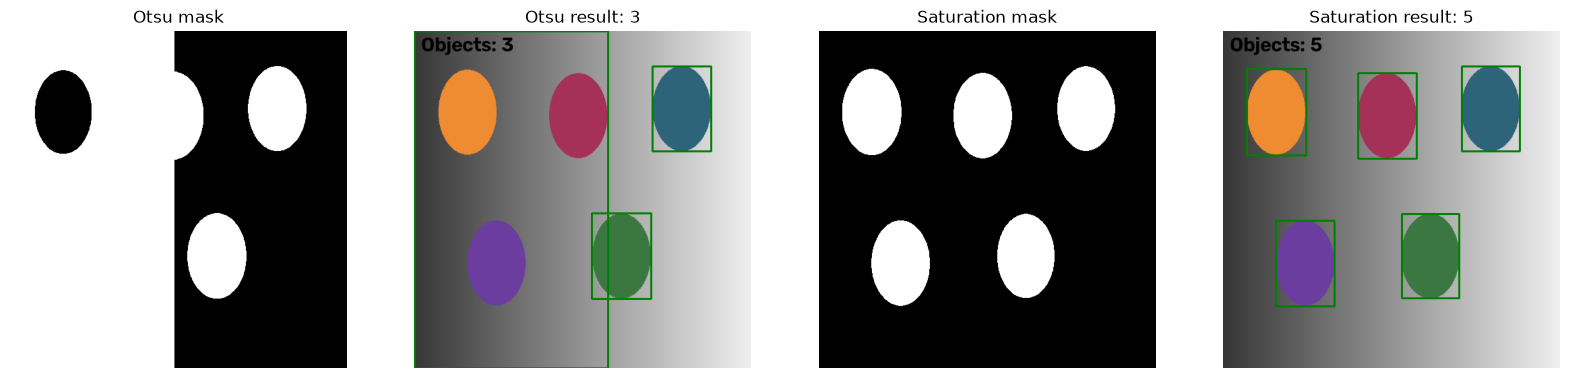

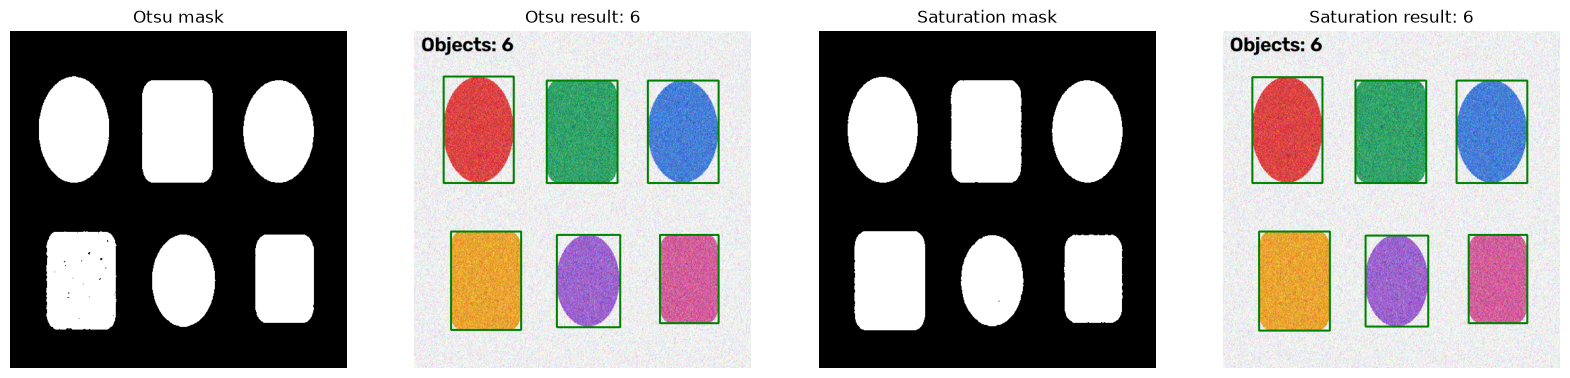

In [20]:
for name in ["02_uneven_lighting.png", "03_noisy_objects.png"]:
    path = os.path.join(IMAGE_DIR, name)
    o1, m1, n1, _ = detect_objects(path, "otsu")
    o2, m2, n2, _ = detect_objects(path, "saturation")
    show_row([m1, o1, m2, o2],
             [f"Otsu mask", f"Otsu result: {n1}", "Saturation mask", f"Saturation result: {n2}"],
             f"task4_challenge_{name[:2]}.png", figsize=(20, 5))

## Results interpretation

| Image | Otsu | Adaptive | Saturation | Expected |
|---|---|---|---|---|
| 02 uneven lighting | 3 | 4 | 5 | 5 |
| 03 noisy | 6 | 6 (205 raw contours) | 6 | 6 |

**Why Otsu did not work for the uneven-lighting image?**

Otsu picks ONE threshold for the whole image. The background in this image is extremely dark in the left side and almost white in the right side, and the histogram doesn't even have one peak in the background and one peak in the object. The single threshold is computed between them, which results in the dark portion of the background being on the "foreground" side. That background plus the two objects touching it into one large white area (approx 125k px) and the only separation between the two objects on the bright side was the black background. This led to 3 regions instead of 5.

**Why adaptive thresholding only partially solved the problem (4 of 5)?**

The adaptive thresholding technique compares each pixel with its own neighbourhood, adapting to the gradient. But it still works on the brightness (grey level) of the colours, and the crimson circle is almost as grey as the surrounding background, so it is almost imperceptible.

**Why the saturation method worked (5 of 5)?**

Saturation is not the brightness of the pixel but how 'colourful' it is. The background is grey/white (low saturation, high darkness/brightness) and all objects are coloured (high saturation, low darkness/brightness). So the lighting gradient has little impact on the saturation mask, and even with the red circle it is clearly distinguished.

**Why both Otsu and saturation worked on the noisy image?**

Otsu and saturation were two examples that worked with the noisy image.
1. The noise is random and small in size and so the Gaussian blur(5×5) smoothes it out before thresholding. Even after blurring, the objects are not close to the background in brightness (Otsu T = 185) and colour.
2. The lighting is uniform, i.e. the assumption of one threshold in Otsu's is valid.
3. Any remaining specks are removed with the contour area filter (MIN_AREA = 500). That is important as an example of adaptive thresholding which gave 205 raw contours (nearly all noise) and only the area filter restored the number of contours to 6.

If blurring alone and a reasonable threshold is sufficient to remove noise, then an area filter will suffice, but if the lighting varies then it requires other means (adaptive or colour based).

# Touching objects comparison

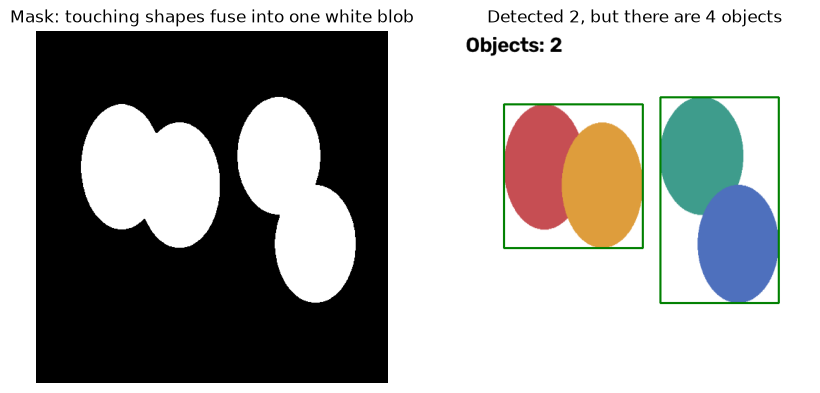

In [21]:
path = os.path.join(IMAGE_DIR, "04_touching_objects.png")
o, m, n, raw = detect_objects(path, "saturation")
show_row([m, o], ["Mask: touching shapes fuse into one white blob", f"Detected {n}, but there are 4 objects"],
         "task4_touching_failure.png", figsize=(10, 5))

## Results interpretation

The numbers we expect is 4, but we received 2 (Otsu and saturation) and 3 (adaptive).

The use of the function cv2.findContours used to detect the connected regions of white pixels. It is unable to learn that a region is composed of multiple objects. In this image if the shapes overlap in pairs, each pair is one blob with one contour with one object counted per blob, (2 blob = 2 object). Another, more adaptive failure is that the same colours overlapped and affected local brightness, and split one blob unequally. Contours are boundaries of connected areas and not "objects" in a human sense of the word. This isn't a problem with the thresholds, as any threshold won't be able to separate two regions that are already connected in the mask.

Geographical form doesn't help either – the blobs get smaller as they are eroded, but as the circles overlap quite a lot it would be necessary to erode a lot before the pairs split off each other.

Which of the following can be added to help detect touching objects:
1. **Distance transform + watershed (best option):** The centre of each object is far from the background, so each object forms a peak in the distance map and there is a shallow dip (neck) between the overlapping objects. Watershed traces a dividing line through each of the necks using the peaks as seeds. On our own test this returned the correct count on this image and maintained the correct counts on the other four images.
2. **cv2.HoughCircles (Hough circle transform):** It is suitable when the objects are circular.
3. **Convexity defects:** concave notches occur at the points where two shapes meet; these can be used to cut the blob.
4. **Colour based splitting:** each object here is different in colour and splitting by colour would separate the pairs (but if two touching objects are the same colour, splitting by colour would not work).
5. **Area based estimate:** Take a blob and divide it into the typical single object area (only an approximation).

**Limitation of all these:** Two objects if they overlap near to their entire area, it is hard to distinguish them using shape method.

# Morphology

[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
BEFORE morphology: valid = 6 | raw contours = 205
AFTER  morphology: valid = 6 | raw contours = 6


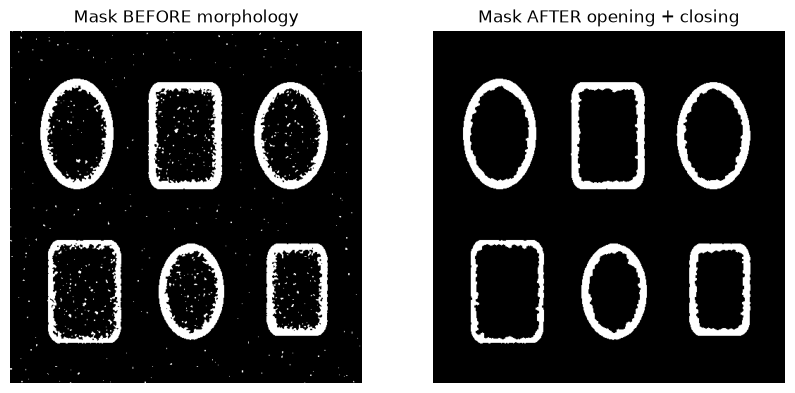

In [22]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
print(kernel)

def count_valid(m, min_area=MIN_AREA):
    cnts, _ = cv2.findContours(m.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return len([c for c in cnts if cv2.contourArea(c) >= min_area]), len(cnts)

# Test on the noisy image with adaptive threshold
noisy_img = cv2.resize(cv2.imread(os.path.join(IMAGE_DIR, "03_noisy_objects.png")), (500, 500))
before = make_mask(noisy_img, "adaptive")
opened = cv2.morphologyEx(before, cv2.MORPH_OPEN, kernel)
after  = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

print("BEFORE morphology: valid =", count_valid(before)[0], "| raw contours =", count_valid(before)[1])
print("AFTER  morphology: valid =", count_valid(after)[0],  "| raw contours =", count_valid(after)[1])
show_row([before, after], ["Mask BEFORE morphology", "Mask AFTER opening + closing"],
         "bonus_morphology.png", figsize=(10, 5))

The opening and closing using 5×5 elliptical kernel removed 200 noise specks (raw contours 205 -> 6). The area filter already had 6 as a valid count and the final count didn't change, but the mask is much cleaner. The touching objects cannot be separated by morphology.

# Additional Information

### Output images saved in the `outputs` folder

| File | What it shows |
|---|---|
| `task1_original.png` | The original image as loaded (700×480) |
| `task1_resized.png` | The image resized to exactly 500×500 |
| `task1_gray.png` | The grayscale version of the resized image |
| `task1_blur_comparison.png` | Grayscale vs Gaussian blur 5×5 (used) vs 15×15 (too strong) |
| `task2_global.png` | Blurred gray, global threshold T = 180 (manual) and Otsu T = 191 |
| `task2_adaptive.png` | Adaptive threshold result (block size 51, C = 10) |
| `task2_compare_01.png` | Clean image: original, global Otsu and adaptive side by side |
| `task2_compare_02.png` | Uneven-lighting image: original, global Otsu (fails) and adaptive |
| `task3_sobel.png` | Sobel X (vertical edges), Sobel Y (horizontal edges) and the combined magnitude |
| `task3_canny.png` | Sobel magnitude compared with Canny (50/150) |
| `task3_noise_comparison.png` | Sobel and Canny on the noisy image, with and without blur |
| `task3_canny_thresholds.png` | Canny on the noisy image with low, medium and strict thresholds |
| `task4_mask.png` | The resized image and its foreground mask (objects white) |
| `task4_final_01.png` | Final result on the clean image: 6 boxes and "Objects: 6" |
| `task4_challenge_02.png` | Uneven lighting: Otsu mask/result (3) vs saturation mask/result (5) |
| `task4_challenge_03.png` | Noisy image: Otsu mask/result (6) vs saturation mask/result (6) |
| `task4_touching_failure.png` | Touching objects fuse into blobs in the mask, so only 2 are counted instead of 4 |
| `bonus_morphology.png` | Noisy adaptive mask before and after opening + closing (5×5 ellipse) |
| `final_01_count6.png` … `final_05_count6.png` | Final bounding-box and count image for each of the five samples (file name ends with the detected count) |